Found 2000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.
Classes: ['cats', 'dogs']


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_1 (RandomFlip)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 158, 158, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 79, 79, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 77, 77, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 38, 38, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 36, 36, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 41472)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     5,308,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,401,921 (20.61 MB)

 Trainable params: 5,401,921 (20.61 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 117s 2s/step - accuracy: 0.5035 - loss: 0.7072 - val_accuracy: 0.5440 - val_loss: 0.6868
Epoch 2/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 114s 2s/step - accuracy: 0.5610 - loss: 0.6868 - val_accuracy: 0.6250 - val_loss: 0.6590
Epoch 3/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 146s 2s/step - accuracy: 0.6445 - loss: 0.6379 - val_accuracy: 0.6710 - val_loss: 0.5962
Epoch 4/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 142s 2s/step - accuracy: 0.6955 - loss: 0.5876 - val_accuracy: 0.7060 - val_loss: 0.5685
Epoch 5/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 142s 2s/step - accuracy: 0.7310 - loss: 0.5411 - val_accuracy: 0.6910 - val_loss: 0.5851
32/32 ━━━━━━━━━━━━━━━━━━━━ 14s 440ms/step - accuracy: 0.6910 - loss: 0.5851
Validation Loss: 0.5851
Validation Accuracy: 69.1 %


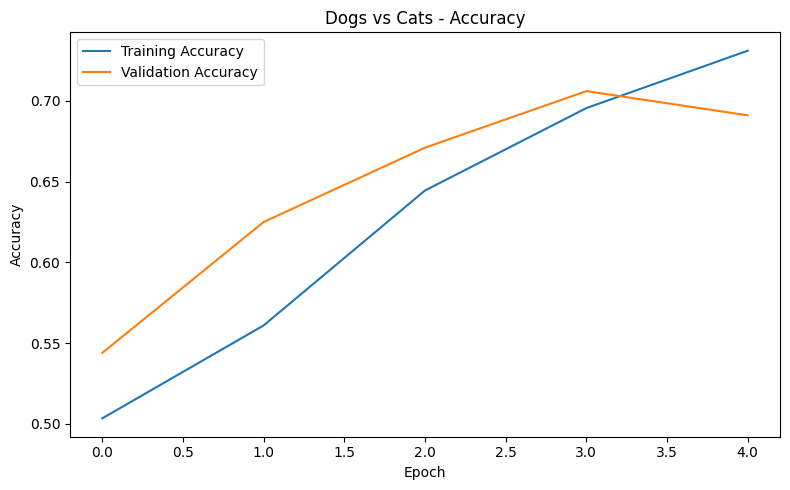

32/32 ━━━━━━━━━━━━━━━━━━━━ 14s 440ms/step


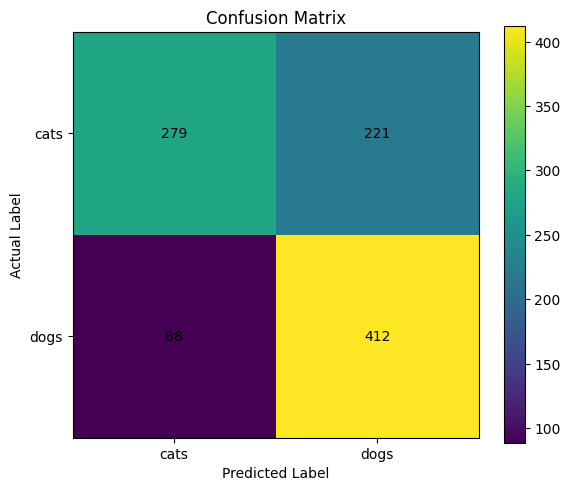

              precision    recall  f1-score   support

        cats       0.76      0.56      0.64       500
        dogs       0.65      0.82      0.73       500

    accuracy                           0.69      1000
   macro avg       0.71      0.69      0.69      1000
weighted avg       0.71      0.69      0.69      1000


PROJECT COMPLETED SUCCESSFULLY!
Model: /content/dogs_vs_cats_model.keras
Accuracy graph: /content/accuracy_curve.png
Confusion matrix: /content/confusion_matrix.png


In [4]:
# TASK 2: DOGS VS CATS CLASSIFICATION

import os
import zipfile
import urllib.request
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix, classification_report

# 1. Download dataset using the alternative URL
url = (
    "https://download.mlcc.google.com/"
    "mledu-datasets/cats_and_dogs_filtered.zip"
)

zip_path = "/content/cats_and_dogs_filtered.zip"
data_dir = "/content/cats_and_dogs_filtered"

print("Downloading Cats and Dogs dataset...")

if not os.path.isdir(os.path.join(data_dir, "train")):
    urllib.request.urlretrieve(url, zip_path)

    print("Download completed. Extracting files...")

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall("/content")

    print("Dataset extracted successfully!")

# 2. Set dataset paths
train_dir = os.path.join(data_dir, "train")
val_dir = os.path.join(data_dir, "validation")

assert os.path.isdir(train_dir), "Training folder not found"
assert os.path.isdir(val_dir), "Validation folder not found"

# 3. Load images
IMG_SIZE = (160, 160)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names
print("Classes:", class_names)

# Improve data loading performance
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)

# 4. Build CNN model
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(160, 160, 3)),
    tf.keras.layers.Rescaling(1.0 / 255),
    tf.keras.layers.RandomFlip("horizontal"),

    tf.keras.layers.Conv2D(32, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(64, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(128, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

# 5. Compile model
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# 6. Train model
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

# 7. Evaluate model
loss, accuracy = model.evaluate(val_ds)

print("Validation Loss:", round(float(loss), 4))
print("Validation Accuracy:", round(float(accuracy) * 100, 2), "%")

# 8. Save accuracy graph
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Dogs vs Cats - Accuracy")
plt.legend()
plt.tight_layout()
plt.savefig("/content/accuracy_curve.png")
plt.show()

# 9. Confusion matrix
y_true = np.concatenate([
    labels.numpy() for images, labels in val_ds
])

y_prob = model.predict(val_ds).ravel()
y_pred = (y_prob >= 0.5).astype(int)

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
plt.imshow(cm, interpolation="nearest")
plt.title("Confusion Matrix")
plt.colorbar()
plt.xticks([0, 1], class_names)
plt.yticks([0, 1], class_names)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

for i in range(2):
    for j in range(2):
        plt.text(j, i, str(cm[i, j]),
                 ha="center", va="center")

plt.tight_layout()
plt.savefig("/content/confusion_matrix.png")
plt.show()

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

# 10. Save trained model
model.save("/content/dogs_vs_cats_model.keras")

print("\nPROJECT COMPLETED SUCCESSFULLY!")
print("Model: /content/dogs_vs_cats_model.keras")
print("Accuracy graph: /content/accuracy_curve.png")
print("Confusion matrix: /content/confusion_matrix.png")

In [5]:
from google.colab import files
files.download("/content/dogs_vs_cats_model.keras")
files.download("/content/accuracy_curve.png")
files.download("/content/confusion_matrix.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>